Download Dentex Challenge 2023 dataset by Ibrahim Ethem Hamamci from Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("truthisneverlinear/dentex-challenge-2023")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dentex-challenge-2023' dataset.
Path to dataset files: /kaggle/input/dentex-challenge-2023


Verify the Dataset

In [ ]:
import os

path = "/root/.cache/kagglehub/datasets/truthisneverlinear/dentex-challenge-2023/versions/1"
path = "/kaggle/input/dentex-challenge-2023"

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for name in files[:5]:
            print("  " * (level + 1) + name)

dentex-challenge-2023/
  validation_data/
    validation_data/
  training_data/
    training_data/


Get Annotations

In [ ]:
import os

base = os.path.join(path, "training_data")

for root, dirs, files in os.walk(base):
    for name in files:
        if "disease" in name.lower() and name.endswith(".json"):
            print("Disease annotation file:", os.path.join(root, name))

Disease annotation file: /kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json


Check all Images

In [ ]:
import os

base = os.path.join(path, "training_data")

for root, dirs, files in os.walk(base):
    images = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    if images:
        print("Image folder:", root)
        print("Image count:", len(images))
        print("Examples:", images[:5])

Image folder: /kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant_enumeration/xrays
Image count: 634
Examples: ['train_429.png', 'train_407.png', 'train_409.png', 'train_369.png', 'train_557.png']
Image folder: /kaggle/input/dentex-challenge-2023/training_data/training_data/unlabelled/xrays
Image count: 1571
Examples: ['train_1117.png', 'train_429.png', 'train_407.png', 'train_409.png', 'train_1515.png']
Image folder: /kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/xrays
Image count: 705
Examples: ['train_429.png', 'train_407.png', 'train_409.png', 'train_677.png', 'train_369.png']
Image folder: /kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant/xrays
Image count: 693
Examples: ['train_429.png', 'train_407.png', 'train_409.png', 'train_677.png', 'train_369.png']


Verify Number of Images and Annotations

In [ ]:
import json
import os

annotation_path = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease",
    "train_quadrant_enumeration_disease.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("Images:", len(data["images"]))
print("Annotations:", len(data["annotations"]))
print("Disease classes:", [c["name"] for c in data["categories_3"]])

Images: 705
Annotations: 3529
Disease classes: ['Impacted', 'Caries', 'Periapical Lesion', 'Deep Caries']


Generate Masks

In [ ]:
import os
import json
import cv2
import numpy as np
from tqdm.auto import tqdm

base_path = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease"
)

image_dir = os.path.join(base_path, "xrays")
json_path = os.path.join(base_path, "train_quadrant_enumeration_disease.json")
mask_dir = os.path.join(base_path, "masks")
os.makedirs(mask_dir, exist_ok=True)

with open(json_path, "r") as f:
    data = json.load(f)

images = {img["id"]: img for img in data["images"]}
masks_by_image = {}

for ann in data["annotations"]:
    image_id = ann["image_id"]
    masks_by_image.setdefault(image_id, []).append(ann)

for image_id, img_info in tqdm(images.items(), desc="Generating masks"):
    image_path = os.path.join(image_dir, img_info["file_name"])
    image = cv2.imread(image_path)

    if image is None:
        continue

    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in masks_by_image.get(image_id, []):
        class_id = int(ann["category_id_3"]) + 1

        for polygon in ann.get("segmentation", []):
            points = np.asarray(polygon, dtype=np.float32).reshape(-1, 2)
            points = np.round(points).astype(np.int32)
            cv2.fillPoly(mask, [points], class_id)

    mask_path = os.path.join(
        mask_dir, os.path.splitext(img_info["file_name"])[0] + ".png"
    )
    cv2.imwrite(mask_path, mask)

print("Masks generated:", len(os.listdir(mask_dir)))
print("Mask folder:", mask_dir)
print("Expected pixel labels: 0=background, 1–4=disease classes")

OSError: [Errno 30] Read-only file system: '/kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/masks'

Mask Generation from caches dataset

In [ ]:
import os
import json
import cv2
import numpy as np
from tqdm.auto import tqdm

from google.colab import drive
drive.mount('/content/drive')

# Read-only dataset location
base_path = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease"
)

image_dir = os.path.join(base_path, "xrays")
json_path = os.path.join(
    base_path, "train_quadrant_enumeration_disease.json"
)

# Writable location on Google Drive
mask_dir = (
    "/content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/masks"
)
os.makedirs(mask_dir, exist_ok=True)

with open(json_path, "r") as f:
    data = json.load(f)

images = {img["id"]: img for img in data["images"]}
masks_by_image = {}

for ann in data["annotations"]:
    image_id = ann["image_id"]
    masks_by_image.setdefault(image_id, []).append(ann)

for image_id, img_info in tqdm(
    images.items(), desc="Generating masks"
):
    image_path = os.path.join(image_dir, img_info["file_name"])
    image = cv2.imread(image_path)

    if image is None:
        continue

    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in masks_by_image.get(image_id, []):
        class_id = int(ann["category_id_3"]) + 1

        for polygon in ann.get("segmentation", []):
            points = np.asarray(
                polygon, dtype=np.float32
            ).reshape(-1, 2)

            points = np.round(points).astype(np.int32)
            cv2.fillPoly(mask, [points], class_id)

    mask_path = os.path.join(
        mask_dir,
        os.path.splitext(img_info["file_name"])[0] + ".png"
    )

    cv2.imwrite(mask_path, mask)

print("Masks generated:", len(os.listdir(mask_dir)))
print("Mask folder:", mask_dir)
print("Expected pixel labels: 0=background, 1–4=disease classes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Generating masks:   0%|          | 0/705 [00:00<?, ?it/s]

Masks generated: 705
Mask folder: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/masks
Expected pixel labels: 0=background, 1–4=disease classes


Verify Mask for 1 image

In [ ]:
import os
import cv2
import numpy as np

mask_dir = (
    "/root/.cache/kagglehub/datasets/truthisneverlinear/"
    "dentex-challenge-2023/versions/1/training_data/"
    "training_data/quadrant-enumeration-disease/masks"
)


# if using a cached dataset
mask_dir = (
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/masks"
)

mask_files = sorted(
    f for f in os.listdir(mask_dir) if f.endswith(".png")
)

sample_mask = cv2.imread(
    os.path.join(mask_dir, mask_files[0]),
    cv2.IMREAD_UNCHANGED
)

print("Total masks:", len(mask_files))
print("Sample mask shape:", sample_mask.shape)
print("Unique pixel labels:", np.unique(sample_mask))
print("Mask data type:", sample_mask.dtype)

Total masks: 705
Sample mask shape: (1316, 2850)
Unique pixel labels: [0 2]
Mask data type: uint8


Verify Masks for All Images

In [ ]:
import os
import cv2
import numpy as np
from collections import Counter

mask_dir = (
    "/root/.cache/kagglehub/datasets/truthisneverlinear/"
    "dentex-challenge-2023/versions/1/training_data/"
    "training_data/quadrant-enumeration-disease/masks"
)
# if using a cached dataset
mask_dir = (
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/masks"
)

label_counts = Counter()

for filename in os.listdir(mask_dir):
    if filename.endswith(".png"):
        mask = cv2.imread(
            os.path.join(mask_dir, filename),
            cv2.IMREAD_UNCHANGED
        )
        label_counts.update(np.unique(mask).tolist())

print("Labels found across all masks:", sorted(label_counts.keys()))
print("Number of masks checked:", len([
    f for f in os.listdir(mask_dir) if f.endswith(".png")
]))
print("Pixel presence by label:", dict(sorted(label_counts.items())))

Labels found across all masks: [0, 1, 2, 3, 4]
Number of masks checked: 705
Pixel presence by label: {0: 705, 1: 254, 2: 623, 3: 116, 4: 320}


Visualize an X-ray and its mask

TypeError: Image data of dtype object cannot be converted to float

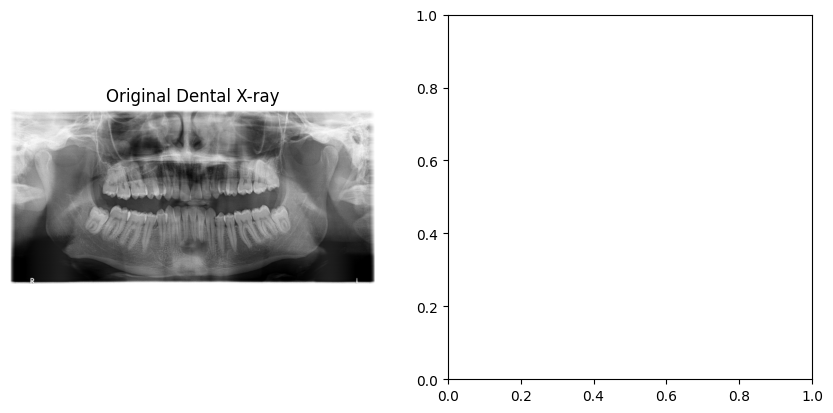

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

base_path = (
    "/root/.cache/kagglehub/datasets/truthisneverlinear/"
    "dentex-challenge-2023/versions/1/training_data/"
    "training_data/quadrant-enumeration-disease"
)

image_name = "train_673.png"

image = cv2.imread(os.path.join(base_path, "xrays", image_name))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask_path = os.path.join(
    base_path, "masks",
    os.path.splitext(image_name)[0] + ".png"
)
mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Dental X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="viridis", vmin=0, vmax=4, interpolation="nearest")
plt.title("Disease Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="viridis", vmin=0, vmax=4, alpha=0.45)
plt.title("X-ray + Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Visualize an X-ray and its mask (with a cached dataset)

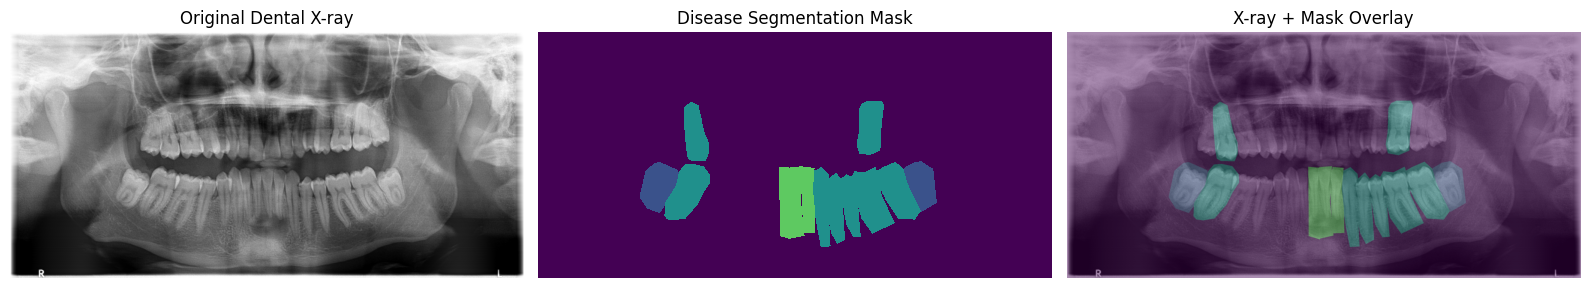

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Original dataset location (read-only)
base_path = (
    "/kaggle/input/dentex-challenge-2023/"
    "training_data/training_data/quadrant-enumeration-disease"
)

image_name = "train_673.png"

# Load original X-ray
image_path = os.path.join(base_path, "xrays", image_name)
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Could not load X-ray: {image_path}")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Load mask from Google Drive
mask_path = os.path.join(
    "/content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/masks",
    os.path.splitext(image_name)[0] + ".png"
)

mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

if mask is None:
    raise FileNotFoundError(f"Could not load mask: {mask_path}")

# Display X-ray, mask, and overlay
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Dental X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    mask, cmap="viridis", vmin=0, vmax=4,
    interpolation="nearest"
)
plt.title("Disease Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(
    mask, cmap="viridis", vmin=0, vmax=4, alpha=0.45
)
plt.title("X-ray + Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Check image and mask dimensions

In [ ]:
import os
import cv2

base_path = (
    "/root/.cache/kagglehub/datasets/truthisneverlinear/"
    "dentex-challenge-2023/versions/1/training_data/"
    "training_data/quadrant-enumeration-disease"
)

image_dir = os.path.join(base_path, "xrays")
mask_dir = os.path.join(base_path, "masks")

image_files = sorted(
    f for f in os.listdir(image_dir) if f.endswith(".png")
)

mismatches = []

for filename in image_files:
    image = cv2.imread(os.path.join(image_dir, filename))
    mask = cv2.imread(
        os.path.join(mask_dir, filename),
        cv2.IMREAD_UNCHANGED
    )

    if image is None or mask is None:
        mismatches.append((filename, "Missing or unreadable file"))
    elif image.shape[:2] != mask.shape[:2]:
        mismatches.append(
            (filename, image.shape[:2], mask.shape[:2])
        )

print("Images checked:", len(image_files))
print("Dimension mismatches:", len(mismatches))
print("Examples:", mismatches[:5])

Images checked: 705
Dimension mismatches: 0
Examples: []


Check image and mask dimensions (using a cached dataset)

In [ ]:
import os
import cv2

# Original X-ray dataset (read-only)
base_path = (
    "/kaggle/input/dentex-challenge-2023/"
    "training_data/training_data/quadrant-enumeration-disease"
)

image_dir = os.path.join(base_path, "xrays")

# Masks generated and saved on Google Drive
mask_dir = (
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/masks"
)

image_files = sorted(
    f for f in os.listdir(image_dir)
    if f.lower().endswith(".png")
)

mismatches = []

for filename in image_files:
    image_path = os.path.join(image_dir, filename)

    # Masks use the same filename as the X-ray
    mask_filename = os.path.splitext(filename)[0] + ".png"
    mask_path = os.path.join(mask_dir, mask_filename)

    image = cv2.imread(image_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

    if image is None or mask is None:
        mismatches.append(
            (filename, "Missing or unreadable image/mask")
        )
    elif image.shape[:2] != mask.shape[:2]:
        mismatches.append(
            (filename, image.shape[:2], mask.shape[:2])
        )

print("Images checked:", len(image_files))
print("Dimension mismatches:", len(mismatches))
print("Examples:", mismatches[:5])

Images checked: 705
Dimension mismatches: 0
Examples: []


Check the class distribution

In [ ]:
import os
import json
from collections import Counter

base_path = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease"
)

json_path = os.path.join(
    base_path, "train_quadrant_enumeration_disease.json"
)

with open(json_path, "r") as f:
    data = json.load(f)

categories = {
    int(category["id"]): category["name"]
    for category in data["categories_3"]
}

image_ids_by_class = {
    class_id: set() for class_id in categories
}

for ann in data["annotations"]:
    class_id = int(ann["category_id_3"])
    image_ids_by_class[class_id].add(ann["image_id"])

print("Total X-ray images:", len(data["images"]))
print("\nImages containing each disease class:")

for class_id, name in sorted(categories.items()):
    print(f"{name}: {len(image_ids_by_class[class_id])} images")

Total X-ray images: 705

Images containing each disease class:
Impacted: 254 images
Caries: 623 images
Periapical Lesion: 116 images
Deep Caries: 321 images


Create the train/validation split

In [ ]:
import os
import json
import numpy as np
from sklearn.model_selection import train_test_split

base_path = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease"
)

json_path = os.path.join(
    base_path, "train_quadrant_enumeration_disease.json"
)

with open(json_path, "r") as f:
    data = json.load(f)

image_names = [img["file_name"] for img in data["images"]]

train_names, val_names = train_test_split(
    image_names,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training images:", len(train_names))
print("Validation images:", len(val_names))
print("Total:", len(train_names) + len(val_names))

Training images: 564
Validation images: 141
Total: 705


Set up the PyTorch environment

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable — CPU mode")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Install the segmentation library

In [ ]:
%pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.9 MB/s eta 0:00:00


Verify DeepLabV3+ support

In [ ]:
import segmentation_models_pytorch as smp
import torch

print("SMP version:", smp.__version__)
print("DeepLabV3+ available:", hasattr(smp, "DeepLabV3Plus"))
print("GPU available:", torch.cuda.is_available())

SMP version: 0.5.0
DeepLabV3+ available: True
GPU available: True


Build our first layer: Conv-BatchNorm-ReLU

In [ ]:
import torch
import torch.nn as nn

class ConvBNReLU(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        dilation=1
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            dilation=dilation,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x


# Test our first building block
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

block = ConvBNReLU(
    in_channels=3,
    out_channels=64
).to(device)

sample = torch.randn(1, 3, 256, 256, device=device)
output = block(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in block.parameters() if p.requires_grad
))

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 64, 256, 256])
Device: cuda
Trainable parameters: 1856


Build the residual block from scratch

In [ ]:
import torch
import torch.nn as nn


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # First convolution
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # Second convolution
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut adjusts dimensions when necessary
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = self.relu(out)

        return out


# Test the residual block
block = ResidualBlock(
    in_channels=64,
    out_channels=128,
    stride=2
).to(device)

sample = torch.randn(1, 64, 256, 256, device=device)
output = block(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Trainable parameters:", sum(
    p.numel() for p in block.parameters() if p.requires_grad
))

Input shape: torch.Size([1, 64, 256, 256])
Output shape: torch.Size([1, 128, 128, 128])
Trainable parameters: 230144


Build the encoder's initial convolution layer

In [ ]:
import torch
import torch.nn as nn


class InitialConvLayer(nn.Module):
    def __init__(self, in_channels=3, out_channels=64):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x


# Test the initial convolution
initial_layer = InitialConvLayer().to(device)

sample = torch.randn(1, 3, 256, 256, device=device)
output = initial_layer(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Trainable parameters:", sum(
    p.numel() for p in initial_layer.parameters()
    if p.requires_grad
))

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 64, 128, 128])
Trainable parameters: 9536


Build the encoder's max-pooling layer

In [ ]:
import torch
import torch.nn as nn

class EncoderMaxPool(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(
            kernel_size=3,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.pool(x)


# Test the max-pooling layer
maxpool = EncoderMaxPool().to(device)

sample = torch.randn(1, 64, 128, 128, device=device)
output = maxpool(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Trainable parameters:", sum(
    p.numel() for p in maxpool.parameters()
    if p.requires_grad
))

Input shape: torch.Size([1, 64, 128, 128])
Output shape: torch.Size([1, 64, 64, 64])
Trainable parameters: 0


Combine the initial convolution and max pooling

In [ ]:
import torch
import torch.nn as nn

class EncoderStem(nn.Module):
    def __init__(self):
        super().__init__()

        self.initial_conv = InitialConvLayer(
            in_channels=3,
            out_channels=64
        )

        self.maxpool = EncoderMaxPool()

    def forward(self, x):
        x = self.initial_conv(x)
        x = self.maxpool(x)
        return x


# Test the complete encoder stem
stem = EncoderStem().to(device)

sample = torch.randn(1, 3, 256, 256, device=device)
output = stem(sample)

print("Input shape:", sample.shape)
print("Stem output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in stem.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 3, 256, 256])
Stem output shape: torch.Size([1, 64, 64, 64])
Trainable parameters: 9536


Build Encoder Stage 1

In [ ]:
import torch
import torch.nn as nn


class EncoderStage1(nn.Module):
    def __init__(self, channels=64):
        super().__init__()

        self.blocks = nn.Sequential(
            ResidualBlock(channels, channels, stride=1),
            ResidualBlock(channels, channels, stride=1)
        )

    def forward(self, x):
        return self.blocks(x)


# Test Encoder Stage 1
stage1 = EncoderStage1().to(device)

sample = torch.randn(1, 64, 64, 64, device=device)
output = stage1(sample)

print("Input shape:", sample.shape)
print("Stage 1 output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in stage1.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 64, 64, 64])
Stage 1 output shape: torch.Size([1, 64, 64, 64])
Trainable parameters: 147968


Build Encoder Stage 2

In [ ]:
import torch
import torch.nn as nn


class EncoderStage2(nn.Module):
    def __init__(self):
        super().__init__()

        self.blocks = nn.Sequential(
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128, stride=1)
        )

    def forward(self, x):
        return self.blocks(x)


# Test Encoder Stage 2
stage2 = EncoderStage2().to(device)

sample = torch.randn(1, 64, 64, 64, device=device)
output = stage2(sample)

print("Input shape:", sample.shape)
print("Stage 2 output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in stage2.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 64, 64, 64])
Stage 2 output shape: torch.Size([1, 128, 32, 32])
Trainable parameters: 525568


Build Encoder Stage 3

In [ ]:
import torch
import torch.nn as nn


class EncoderStage3(nn.Module):
    def __init__(self):
        super().__init__()

        self.blocks = nn.Sequential(
            ResidualBlock(128, 256, stride=2),
            ResidualBlock(256, 256, stride=1)
        )

    def forward(self, x):
        return self.blocks(x)


# Test Encoder Stage 3
stage3 = EncoderStage3().to(device)

sample = torch.randn(1, 128, 32, 32, device=device)
output = stage3(sample)

print("Input shape:", sample.shape)
print("Stage 3 output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in stage3.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 128, 32, 32])
Stage 3 output shape: torch.Size([1, 256, 16, 16])
Trainable parameters: 2099712


Build Encoder Stage 4

In [ ]:
import torch
import torch.nn as nn


class EncoderStage4(nn.Module):
    def __init__(self):
        super().__init__()

        self.blocks = nn.Sequential(
            ResidualBlock(256, 512, stride=2),
            ResidualBlock(512, 512, stride=1)
        )

    def forward(self, x):
        return self.blocks(x)


# Test Encoder Stage 4
stage4 = EncoderStage4().to(device)

sample = torch.randn(1, 256, 16, 16, device=device)
output = stage4(sample)

print("Input shape:", sample.shape)
print("Stage 4 output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in stage4.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 256, 16, 16])
Stage 4 output shape: torch.Size([1, 512, 8, 8])
Trainable parameters: 8393728


Build the ASPP atrous convolution branch

In [ ]:
import torch
import torch.nn as nn


class ASPPConvBranch(nn.Module):
    def __init__(self, in_channels, out_channels, dilation_rate):
        super().__init__()

        self.branch = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=dilation_rate,
                dilation=dilation_rate,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.branch(x)


# Test the ASPP branch
aspp_branch = ASPPConvBranch(
    in_channels=512,
    out_channels=256,
    dilation_rate=6
).to(device)

sample = torch.randn(1, 512, 8, 8, device=device)
output = aspp_branch(sample)

print("Input shape:", sample.shape)
print("ASPP branch output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in aspp_branch.parameters() if p.requires_grad)
)

Input shape: torch.Size([1, 512, 8, 8])
ASPP branch output shape: torch.Size([1, 256, 8, 8])
Trainable parameters: 1180160


Build the second ASPP branch

In [ ]:
import torch

aspp_branch_12 = ASPPConvBranch(
    in_channels=512,
    out_channels=256,
    dilation_rate=12
).to(device)

sample = torch.randn(1, 512, 8, 8, device=device)
output = aspp_branch_12(sample)

print("Input shape:", sample.shape)
print("ASPP branch output shape:", output.shape)
print("Dilation rate:", 12)
print(
    "Trainable parameters:",
    sum(p.numel() for p in aspp_branch_12.parameters()
        if p.requires_grad)
)

Input shape: torch.Size([1, 512, 8, 8])
ASPP branch output shape: torch.Size([1, 256, 8, 8])
Dilation rate: 12
Trainable parameters: 1180160


Build the third ASPP branch

In [ ]:
aspp_branch_18 = ASPPConvBranch(
    in_channels=512,
    out_channels=256,
    dilation_rate=18
).to(device)

sample = torch.randn(1, 512, 8, 8, device=device)
output = aspp_branch_18(sample)

print("Input shape:", sample.shape)
print("ASPP branch output shape:", output.shape)
print("Dilation rate:", 18)
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in aspp_branch_18.parameters()
        if p.requires_grad
    )
)

Input shape: torch.Size([1, 512, 8, 8])
ASPP branch output shape: torch.Size([1, 256, 8, 8])
Dilation rate: 18
Trainable parameters: 1180160


Build the ASPP 1 × 1 convolution branch

In [ ]:
import torch
import torch.nn as nn


class ASPPPointwiseBranch(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.branch = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.branch(x)


# Test the 1 × 1 convolution branch
aspp_branch_1x1 = ASPPPointwiseBranch(
    in_channels=512,
    out_channels=256
).to(device)

sample = torch.randn(1, 512, 8, 8, device=device)
output = aspp_branch_1x1(sample)

print("Input shape:", sample.shape)
print("ASPP branch output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in aspp_branch_1x1.parameters()
        if p.requires_grad)
)

Input shape: torch.Size([1, 512, 8, 8])
ASPP branch output shape: torch.Size([1, 256, 8, 8])
Trainable parameters: 131584


Build the ASPP global pooling branch

In [ ]:
import torch
import torch.nn as nn


class ASPPGlobalPoolingBranch(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.project = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x = self.pool(x)
        x = self.project(x)
        return x


# Test the global pooling branch
aspp_global = ASPPGlobalPoolingBranch(
    in_channels=512,
    out_channels=256
).to(device)

sample = torch.randn(2, 512, 8, 8, device=device)
output = aspp_global(sample)

print("Input shape:", sample.shape)
print("Global pooling output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in aspp_global.parameters()
        if p.requires_grad)
)

Input shape: torch.Size([2, 512, 8, 8])
Global pooling output shape: torch.Size([2, 256, 1, 1])
Trainable parameters: 131584


Combine the five ASPP branches

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ASPP(nn.Module):
    def __init__(self, in_channels=512, out_channels=256):
        super().__init__()

        self.branch1 = ASPPPointwiseBranch(
            in_channels, out_channels
        )
        self.branch6 = ASPPConvBranch(
            in_channels, out_channels, dilation_rate=6
        )
        self.branch12 = ASPPConvBranch(
            in_channels, out_channels, dilation_rate=12
        )
        self.branch18 = ASPPConvBranch(
            in_channels, out_channels, dilation_rate=18
        )
        self.global_branch = ASPPGlobalPoolingBranch(
            in_channels, out_channels
        )

        self.project = nn.Sequential(
            nn.Conv2d(
                out_channels * 5,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        size = x.shape[2:]

        features = [
            self.branch1(x),
            self.branch6(x),
            self.branch12(x),
            self.branch18(x),
            F.interpolate(
                self.global_branch(x),
                size=size,
                mode="bilinear",
                align_corners=False
            )
        ]

        x = torch.cat(features, dim=1)
        return self.project(x)


# Test the complete ASPP module
aspp = ASPP().to(device)

sample = torch.randn(2, 512, 8, 8, device=device)
output = aspp(sample)

print("Input shape:", sample.shape)
print("ASPP output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in aspp.parameters() if p.requires_grad)
)

Input shape: torch.Size([2, 512, 8, 8])
ASPP output shape: torch.Size([2, 256, 8, 8])
Trainable parameters: 4131840


Define a revised EncoderStage4 that preserves the 16×16 spatial resolution using dilated convolutions

In [ ]:
class EncoderStage4(nn.Module):
    def __init__(self, in_channels=256, out_channels=512):
        super().__init__()

        self.block1 = ResidualBlock(
            in_channels, out_channels, stride=1
        )
        self.block1.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=1,
            padding=2, dilation=2, bias=False
        )

        self.block2 = ResidualBlock(
            out_channels, out_channels, stride=1
        )
        self.block2.conv1 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=2, dilation=2, bias=False
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return x


# Test the revised stage
stage4 = EncoderStage4().to(device)
sample = torch.randn(2, 256, 16, 16, device=device)
output = stage4(sample)

print("Input shape:", sample.shape)
print("Stage 4 output shape:", output.shape)

Input shape: torch.Size([2, 256, 16, 16])
Stage 4 output shape: torch.Size([2, 512, 16, 16])


Reduce the encoder’s 64-channel Stage 1 features to 48 channels, as commonly done in the decoder

In [ ]:
class LowLevelProjection(nn.Module):
    def __init__(self, in_channels=64, out_channels=48):
        super().__init__()

        self.projection = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.projection(x)


# Test the low-level feature projection
low_level = LowLevelProjection().to(device)

sample = torch.randn(2, 64, 64, 64, device=device)
output = low_level(sample)

print("Input shape:", sample.shape)
print("Projected output shape:", output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in low_level.parameters() if p.requires_grad)
)

Input shape: torch.Size([2, 64, 64, 64])
Projected output shape: torch.Size([2, 48, 64, 64])
Trainable parameters: 3168


Build the DeepLabV3+ decoder fusion layer

In [ ]:
class DecoderFusion(nn.Module):
    def __init__(self, aspp_channels=256, low_level_channels=48,
                 out_channels=256):
        super().__init__()

        self.fusion = nn.Sequential(
            nn.Conv2d(
                aspp_channels + low_level_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, aspp_features, low_level_features):
        aspp_features = F.interpolate(
            aspp_features,
            size=low_level_features.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        combined = torch.cat(
            [aspp_features, low_level_features],
            dim=1
        )

        return self.fusion(combined)


# Test the decoder fusion layer
decoder_fusion = DecoderFusion().to(device)

aspp_sample = torch.randn(2, 256, 16, 16, device=device)
low_level_sample = torch.randn(2, 48, 64, 64, device=device)

output = decoder_fusion(aspp_sample, low_level_sample)

print("ASPP input shape:", aspp_sample.shape)
print("Low-level input shape:", low_level_sample.shape)
print("Decoder output shape:", output.shape)

ASPP input shape: torch.Size([2, 256, 16, 16])
Low-level input shape: torch.Size([2, 48, 64, 64])
Decoder output shape: torch.Size([2, 256, 64, 64])


Build the segmentation head

In [ ]:
class SegmentationHead(nn.Module):
    def __init__(self, in_channels=256, num_classes=5):
        super().__init__()

        self.classifier = nn.Conv2d(
            in_channels,
            num_classes,
            kernel_size=1
        )

    def forward(self, x, output_size=(256, 256)):
        x = self.classifier(x)

        x = F.interpolate(
            x,
            size=output_size,
            mode="bilinear",
            align_corners=False
        )

        return x


# Test the segmentation head
segmentation_head = SegmentationHead().to(device)

sample = torch.randn(2, 256, 64, 64, device=device)
output = segmentation_head(sample)

print("Decoder input shape:", sample.shape)
print("Segmentation output shape:", output.shape)

Decoder input shape: torch.Size([2, 256, 64, 64])
Segmentation output shape: torch.Size([2, 5, 256, 256])


Assemble the complete DeepLabV3+ model

In [ ]:
class DeepLabV3Plus(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # Encoder
        self.stem = EncoderStem()
        self.stage1 = EncoderStage1()
        self.stage2 = EncoderStage2()
        self.stage3 = EncoderStage3()
        self.stage4 = EncoderStage4()

        # ASPP
        self.aspp = ASPP(
            in_channels=512,
            out_channels=256
        )

        # Decoder
        self.low_level_projection = LowLevelProjection(
            in_channels=64,
            out_channels=48
        )
        self.decoder_fusion = DecoderFusion(
            aspp_channels=256,
            low_level_channels=48,
            out_channels=256
        )

        # Segmentation head
        self.segmentation_head = SegmentationHead(
            in_channels=256,
            num_classes=num_classes
        )

    def forward(self, x):
        input_size = x.shape[2:]

        x = self.stem(x)
        low_level = self.stage1(x)

        x = self.stage2(low_level)
        x = self.stage3(x)
        x = self.stage4(x)

        x = self.aspp(x)
        low_level = self.low_level_projection(low_level)

        x = self.decoder_fusion(x, low_level)
        x = self.segmentation_head(x, output_size=input_size)

        return x


# Instantiate and test the complete model
model = DeepLabV3Plus(num_classes=5).to(device)
model.eval()

with torch.no_grad():
    sample = torch.randn(2, 3, 256, 256, device=device)
    output = model(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)
print("Device:", next(model.parameters()).device)

Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 5, 256, 256])
Total parameters: 16013733
Device: cuda:0


# Training Pipeline — Google Drive Checkpoints + CSV Logging

**This section replaces the old post-model-creation cells.** The original cells from dataset acquisition through the `DeepLabV3Plus` model definition/instantiation (cells 0–69) are preserved unchanged.

This pipeline:
- prepares the existing dataset and train/validation loaders;
- trains the already-created `model`;
- saves `last_checkpoint.pth` after every completed epoch for resuming;
- keeps `best_checkpoint.pth` pointing to the best validation mean foreground Dice model;
- writes one CSV row per completed epoch;
- supports resuming after a Colab runtime/GPU interruption.

> Run these cells in order. Mount Google Drive when prompted. Do not run the old training cells from the original notebook after this section.

## 1. Imports, device, configuration, and Google Drive

Change `MAX_EPOCHS` or other settings here if needed. Keep the model architecture above unchanged.

In [ ]:
import os
import csv
import json
import time
import random
import shutil
import tempfile
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image

# Re-select the current runtime device and move the existing model to it.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Training settings
NUM_CLASSES = 5
IMAGE_SIZE = 256
BATCH_SIZE = 4
MAX_EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
VALIDATION_FRACTION = 0.20
RANDOM_SEED = 42
NUM_WORKERS = 0  # reliable default for Colab notebooks
RESUME_FROM_CHECKPOINT = True

# Google Drive mount
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Google Colab mount helper not found. This notebook is designed to save artifacts to mounted Google Drive.")

DRIVE_ROOT = Path("/content/drive/MyDrive/Dental_Caries_DeepLabV3Plus")
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
LOG_DIR = DRIVE_ROOT / "logs"
PLOT_DIR = DRIVE_ROOT / "plots"
CONFIG_DIR = DRIVE_ROOT / "config"

for folder in (CHECKPOINT_DIR, LOG_DIR, PLOT_DIR, CONFIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "best_checkpoint.pth"
LAST_CHECKPOINT_PATH = CHECKPOINT_DIR / "last_checkpoint.pth"
CSV_PATH = LOG_DIR / "training_history.csv"
CONFIG_PATH = CONFIG_DIR / "training_config.json"

# Persist the configuration used for this run.
TRAINING_CONFIG = {
    "num_classes": NUM_CLASSES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "validation_fraction": VALIDATION_FRACTION,
    "random_seed": RANDOM_SEED,
    "num_workers": NUM_WORKERS,
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau(mode='max', factor=0.5, patience=3)",
    "best_metric": "mean_disease_dice",
    "checkpoint_directory": str(CHECKPOINT_DIR),
}
with CONFIG_PATH.open("w", encoding="utf-8") as f:
    json.dump(TRAINING_CONFIG, f, indent=2)

print("Drive artifact directory:", DRIVE_ROOT)
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Last checkpoint:", LAST_CHECKPOINT_PATH)
print("CSV log:", CSV_PATH)

Device: cuda
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive artifact directory: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus
Best checkpoint: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/checkpoints/best_checkpoint.pth
Last checkpoint: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/checkpoints/last_checkpoint.pth
CSV log: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/logs/training_history.csv


## 2. Dataset paths and integrity checks

These paths match the dataset layout used earlier in the notebook. This cell checks that image/mask pairs exist before training starts.

In [ ]:
import os

DATASET_ROOT = os.path.join(
    path,
    "training_data",
    "training_data",
    "quadrant-enumeration-disease"
)
image_dir = DATASET_ROOT / "xrays"
mask_dir = DATASET_ROOT / "masks"

if not image_dir.is_dir():
    raise FileNotFoundError(
        f"Image directory not found: {image_dir}\n"
        "Run the existing dataset-acquisition cells (0–69) first, or update DATASET_ROOT."
    )
if not mask_dir.is_dir():
    raise FileNotFoundError(
        f"Mask directory not found: {mask_dir}\n"
        "Run the existing mask-generation cells first, or update DATASET_ROOT."
    )

valid_image_extensions = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
image_files = sorted(
    f for f in os.listdir(image_dir)
    if f.lower().endswith(valid_image_extensions)
)
mask_files = sorted(
    f for f in os.listdir(mask_dir)
    if f.lower().endswith((".png", ".tif", ".tiff"))
)

if not image_files:
    raise RuntimeError(f"No images found in {image_dir}")
if not mask_files:
    raise RuntimeError(f"No masks found in {mask_dir}")

mask_stems = {Path(f).stem for f in mask_files}
missing_masks = [f for f in image_files if Path(f).stem not in mask_stems]
if missing_masks:
    raise RuntimeError(
        f"{len(missing_masks)} images have no same-stem mask. "
        f"Examples: {missing_masks[:5]}"
    )

print(f"Images found: {len(image_files)}")
print(f"Masks found:  {len(mask_files)}")
print("Image directory:", image_dir)
print("Mask directory:", mask_dir)

TypeError: unsupported operand type(s) for /: 'str' and 'str'

## 2. Dataset paths and integrity checks (when using cached dataset)

These paths match the dataset layout used earlier in the notebook. This cell checks that image/mask pairs exist before training starts.

In [ ]:
import os
from pathlib import Path

# Original X-ray dataset location
DATASET_ROOT = Path(
    "/kaggle/input/dentex-challenge-2023/"
    "training_data/training_data/quadrant-enumeration-disease"
)

image_dir = DATASET_ROOT / "xrays"

# Masks generated and saved on Google Drive
mask_dir = Path(
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/masks"
)

if not image_dir.is_dir():
    raise FileNotFoundError(
        f"Image directory not found: {image_dir}\n"
        "Check the dataset path and ensure the dataset is accessible."
    )

if not mask_dir.is_dir():
    raise FileNotFoundError(
        f"Mask directory not found: {mask_dir}\n"
        "Run the mask-generation cell first and check the Google Drive path."
    )

valid_image_extensions = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

image_files = sorted(
    f for f in os.listdir(image_dir)
    if f.lower().endswith(valid_image_extensions)
)

mask_files = sorted(
    f for f in os.listdir(mask_dir)
    if f.lower().endswith((".png", ".tif", ".tiff"))
)

if not image_files:
    raise RuntimeError(f"No images found in {image_dir}")

if not mask_files:
    raise RuntimeError(f"No masks found in {mask_dir}")

mask_stems = {Path(f).stem for f in mask_files}

missing_masks = [
    f for f in image_files
    if Path(f).stem not in mask_stems
]

if missing_masks:
    raise RuntimeError(
        f"{len(missing_masks)} images have no same-stem mask. "
        f"Examples: {missing_masks[:5]}"
    )

print(f"Images found: {len(image_files)}")
print(f"Masks found:  {len(mask_files)}")
print("Image directory:", image_dir)
print("Mask directory:", mask_dir)

Images found: 705
Masks found:  705
Image directory: /kaggle/input/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/xrays
Mask directory: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/masks


## 3. Dataset class and train/validation split

Images are resized with bilinear interpolation; segmentation masks use nearest-neighbor interpolation so class IDs are not blended.

In [ ]:
class DentalSegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_files, image_size=256):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.image_files = list(image_files)
        self.image_size = int(image_size)

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        filename = self.image_files[index]
        image_path = self.image_dir / filename
        mask_path = self.mask_dir / f"{Path(filename).stem}.png"

        if not mask_path.exists():
            # Support masks saved with tif/tiff extensions if the dataset uses them.
            candidates = [
                self.mask_dir / f"{Path(filename).stem}.tif",
                self.mask_dir / f"{Path(filename).stem}.tiff",
            ]
            mask_path = next((p for p in candidates if p.exists()), None)
            if mask_path is None:
                raise FileNotFoundError(f"No mask found for image: {image_path}")

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = image.resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )
            image = np.asarray(image, dtype=np.float32) / 255.0

        with Image.open(mask_path) as mask:
            mask = mask.resize(
                (self.image_size, self.image_size),
                Image.Resampling.NEAREST
            )
            mask = np.asarray(mask, dtype=np.int64)

        # If a mask is unexpectedly RGB/palette-expanded, fail loudly rather than silently training on wrong labels.
        if mask.ndim != 2:
            raise ValueError(
                f"Mask must be a 2-D class-ID image, got shape {mask.shape}: {mask_path}"
            )
        if not np.isin(np.unique(mask), np.arange(NUM_CLASSES)).all():
            raise ValueError(
                f"Unexpected class IDs in {mask_path}: {np.unique(mask).tolist()}"
            )

        image_tensor = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        mask_tensor = torch.from_numpy(mask).long()
        return image_tensor, mask_tensor


dataset = DentalSegmentationDataset(
    image_dir=image_dir,
    mask_dir=mask_dir,
    image_files=image_files,
    image_size=IMAGE_SIZE
)

if len(dataset) < 2:
    raise RuntimeError("Need at least two image/mask pairs for a train/validation split.")

train_size = int((1.0 - VALIDATION_FRACTION) * len(dataset))
val_size = len(dataset) - train_size
generator = torch.Generator().manual_seed(RANDOM_SEED)
train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size], generator=generator
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("Total samples:", len(dataset))
print("Training samples:", len(train_dataset), "| batches:", len(train_loader))
print("Validation samples:", len(val_dataset), "| batches:", len(val_loader))

# Verify a real batch before spending GPU time.
sample_images, sample_masks = next(iter(train_loader))
print("Batch image shape:", tuple(sample_images.shape), sample_images.dtype)
print("Batch mask shape:", tuple(sample_masks.shape), sample_masks.dtype)
print("Mask class IDs in batch:", torch.unique(sample_masks).tolist())
assert sample_images.ndim == 4 and sample_images.shape[1] == 3
assert sample_masks.ndim == 3
assert int(sample_masks.min()) >= 0 and int(sample_masks.max()) < NUM_CLASSES

Total samples: 705
Training samples: 564 | batches: 141
Validation samples: 141 | batches: 36
Batch image shape: (4, 3, 256, 256) torch.float32
Batch mask shape: (4, 256, 256) torch.int64
Mask class IDs in batch: [0, 1, 2, 4]


## 4. Class weights, loss, optimizer, and scheduler

Class pixel counts are calculated from the masks instead of using the old hard-coded counts. The class-weighting strategy remains median foreground frequency divided by each class frequency, then normalized.

In [ ]:
class_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for filename in mask_files:
    mask_path = mask_dir / filename
    with Image.open(mask_path) as mask_image:
        mask_array = np.asarray(mask_image, dtype=np.int64)
    if mask_array.ndim != 2:
        raise ValueError(f"Expected a 2-D mask: {mask_path}, got {mask_array.shape}")
    values, counts = np.unique(mask_array, return_counts=True)
    for value, count in zip(values, counts):
        if 0 <= int(value) < NUM_CLASSES:
            class_pixel_counts[int(value)] += int(count)

if np.any(class_pixel_counts == 0):
    raise ValueError(
        f"At least one class has zero pixels: {class_pixel_counts.tolist()}. "
        "Check the mask class IDs before training."
    )

class_frequencies = torch.tensor(class_pixel_counts, dtype=torch.float64)
class_frequencies = class_frequencies / class_frequencies.sum()
median_foreground_frequency = class_frequencies[1:].median()
class_weights = (median_foreground_frequency / class_frequencies).float()
class_weights = class_weights / class_weights.mean()

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

print("Pixel counts:", class_pixel_counts.tolist())
print("Class frequencies:", [round(float(x), 8) for x in class_frequencies])
print("Class weights:", class_weights.tolist())
print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Pixel counts: [2625172261, 17524056, 71260033, 4538942, 16424158]
Class frequencies: [0.95987188, 0.00640752, 0.02605562, 0.00165963, 0.00600535]
Class weights: [0.005400466732680798, 0.8090110421180725, 0.19894960522651672, 3.1234493255615234, 0.863189160823822]
Loss: CrossEntropyLoss()
Optimizer: AdamW
Initial learning rate: 0.0001


## 5. Segmentation metrics

Metrics are accumulated over all validation pixels using a confusion matrix. Class 0 is treated as background; the checkpoint selection metric is mean Dice over classes 1–4.

In [ ]:
def update_confusion_matrix(confusion, logits, targets, num_classes=NUM_CLASSES):
    predictions = torch.argmax(logits, dim=1)
    targets = targets.long()
    valid = (targets >= 0) & (targets < num_classes)
    encoded = num_classes * targets[valid] + predictions[valid]
    batch_confusion = torch.bincount(
        encoded, minlength=num_classes * num_classes
    ).reshape(num_classes, num_classes)
    confusion += batch_confusion
    return confusion


def metrics_from_confusion_matrix(confusion):
    confusion = confusion.to(torch.float64)
    true_positive = torch.diag(confusion)
    actual = confusion.sum(dim=1)
    predicted = confusion.sum(dim=0)
    denominator_dice = actual + predicted
    union = actual + predicted - true_positive

    dice = torch.where(
        denominator_dice > 0,
        2.0 * true_positive / denominator_dice.clamp(min=1e-12),
        torch.zeros_like(true_positive)
    )
    iou = torch.where(
        union > 0,
        true_positive / union.clamp(min=1e-12),
        torch.zeros_like(true_positive)
    )

    return {
        "dice_per_class": dice.cpu().tolist(),
        "iou_per_class": iou.cpu().tolist(),
        "mean_disease_dice": float(dice[1:].mean().item()),
        "mean_disease_iou": float(iou[1:].mean().item()),
    }

## 6. Train and validation functions

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, masks)

        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss: {loss.item()}")

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += float(loss.item()) * batch_size
        total_samples += batch_size

    return total_loss / max(total_samples, 1)


@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device
    )

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, masks)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite validation loss: {loss.item()}")

        batch_size = images.size(0)
        total_loss += float(loss.item()) * batch_size
        total_samples += batch_size
        update_confusion_matrix(confusion, logits, masks, NUM_CLASSES)

    result = metrics_from_confusion_matrix(confusion)
    result["val_loss"] = total_loss / max(total_samples, 1)
    return result

## 7. Safe checkpoint saving and resume helpers

`last_checkpoint.pth` contains the complete state needed to resume training. `best_checkpoint.pth` preserves the best model weights and best validation score. Both files are written to Google Drive after every completed epoch using temporary files followed by an atomic rename.

In [ ]:
def atomic_torch_save(payload, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = destination.with_name(destination.name + ".tmp")
    torch.save(payload, temporary_path)
    os.replace(temporary_path, destination)


def cpu_state_dict(module):
    return {key: value.detach().cpu().clone() for key, value in module.state_dict().items()}


def capture_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda"] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(state):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and state.get("torch_cuda") is not None:
        torch.cuda.set_rng_state_all(state["torch_cuda"])


def load_checkpoint(path):
    # weights_only=False is needed because resume checkpoints include RNG state.
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:  # compatibility with older PyTorch versions
        return torch.load(path, map_location=device)


def checkpoint_csv_row(epoch, train_loss, val_result, learning_rate, epoch_time_sec, best_dice):
    row = {
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_result["val_loss"]),
        "val_dice": float(val_result["mean_disease_dice"]),
        "val_iou": float(val_result["mean_disease_iou"]),
        "learning_rate": float(learning_rate),
        "epoch_time_sec": float(epoch_time_sec),
        "best_val_dice": float(best_dice),
    }
    for class_id in range(NUM_CLASSES):
        row[f"dice_class_{class_id}"] = float(val_result["dice_per_class"][class_id])
        row[f"iou_class_{class_id}"] = float(val_result["iou_per_class"][class_id])
    return row


CSV_FIELDS = [
    "epoch", "train_loss", "val_loss", "val_dice", "val_iou",
    "learning_rate", "epoch_time_sec", "best_val_dice",
] + [
    f"{metric}_class_{class_id}"
    for metric in ("dice", "iou")
    for class_id in range(NUM_CLASSES)
]


def reconcile_csv(completed_epoch, last_metrics=None):
    # Remove any rows beyond the last durable checkpoint and deduplicate by epoch.
    rows_by_epoch = {}
    if CSV_PATH.exists():
        with CSV_PATH.open("r", newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                try:
                    epoch_number = int(row["epoch"])
                except (KeyError, ValueError, TypeError):
                    continue
                if epoch_number <= completed_epoch:
                    rows_by_epoch[epoch_number] = row

    # If a runtime stopped after checkpoint save but before CSV write, restore that row.
    if completed_epoch > 0 and last_metrics is not None and completed_epoch not in rows_by_epoch:
        rows_by_epoch[completed_epoch] = last_metrics

    temporary_csv = CSV_PATH.with_name(CSV_PATH.name + ".tmp")
    with temporary_csv.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        writer.writeheader()
        for epoch_number in sorted(rows_by_epoch):
            row = rows_by_epoch[epoch_number]
            writer.writerow({field: row.get(field, "") for field in CSV_FIELDS})
    os.replace(temporary_csv, CSV_PATH)


def append_csv_row(row):
    # Reconcile first so re-running a cell cannot create duplicate epoch rows.
    existing_epochs = set()
    if CSV_PATH.exists():
        with CSV_PATH.open("r", newline="", encoding="utf-8") as f:
            for existing in csv.DictReader(f):
                try:
                    existing_epochs.add(int(existing["epoch"]))
                except (KeyError, ValueError, TypeError):
                    pass
    if int(row["epoch"]) in existing_epochs:
        return
    with CSV_PATH.open("a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        if f.tell() == 0:
            writer.writeheader()
        writer.writerow({field: row.get(field, "") for field in CSV_FIELDS})
        f.flush()
        os.fsync(f.fileno())

## 8. Resume from the latest checkpoint

Set `RESUME_FROM_CHECKPOINT = False` only if you intentionally want to start a new run. When resuming, the model, optimizer, scheduler, epoch count, best score, and random states are restored.

In [ ]:
start_epoch = 0
best_val_dice = -1.0
best_epoch = 0
best_model_state = None
last_metrics_row = None

if RESUME_FROM_CHECKPOINT and LAST_CHECKPOINT_PATH.exists():
    checkpoint = load_checkpoint(LAST_CHECKPOINT_PATH)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = int(checkpoint["completed_epoch"])
    best_val_dice = float(checkpoint.get("best_val_dice", -1.0))
    best_epoch = int(checkpoint.get("best_epoch", 0))
    best_model_state = checkpoint.get("best_model_state_dict")
    last_metrics_row = checkpoint.get("last_metrics_row")
    restore_rng_state(checkpoint.get("rng_state"))

    print(f"Resumed from completed epoch {start_epoch}.")
    print(f"Best validation Dice so far: {best_val_dice:.6f} (epoch {best_epoch})")
    reconcile_csv(start_epoch, last_metrics_row)
else:
    print("Starting a new training run.")
    reconcile_csv(0)

if best_model_state is None and BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_checkpoint(BEST_CHECKPOINT_PATH)
    best_model_state = best_checkpoint.get("model_state_dict")
    if best_model_state is not None:
        best_val_dice = float(best_checkpoint.get("best_val_dice", best_val_dice))
        best_epoch = int(best_checkpoint.get("best_epoch", best_epoch))

if start_epoch >= MAX_EPOCHS:
    print(f"Checkpoint already reached MAX_EPOCHS={MAX_EPOCHS}. Increase MAX_EPOCHS to continue training.")

Starting a new training run.


## 9. Main training loop

At the end of every completed epoch, the code:
1. computes validation metrics;
2. updates the best-model state if Dice improved;
3. atomically saves **both** checkpoint files to Google Drive;
4. writes the epoch's CSV record.

If an epoch is interrupted before these steps finish, resume starts from the most recent completed epoch.

In [ ]:
try:
    for epoch_index in range(start_epoch, MAX_EPOCHS):
        epoch_number = epoch_index + 1
        epoch_start_time = time.time()
        print(f"\n{'=' * 18} Epoch {epoch_number}/{MAX_EPOCHS} {'=' * 18}")

        train_loss = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )
        val_result = validate_one_epoch(
            model, val_loader, criterion, device
        )

        current_val_dice = float(val_result["mean_disease_dice"])
        improved = current_val_dice > best_val_dice
        if improved:
            best_val_dice = current_val_dice
            best_epoch = epoch_number
            best_model_state = cpu_state_dict(model)

        scheduler.step(current_val_dice)
        current_lr = float(optimizer.param_groups[0]["lr"])
        epoch_time_sec = time.time() - epoch_start_time

        row = checkpoint_csv_row(
            epoch=epoch_number,
            train_loss=train_loss,
            val_result=val_result,
            learning_rate=current_lr,
            epoch_time_sec=epoch_time_sec,
            best_dice=best_val_dice,
        )

        # Full resume checkpoint: latest completed model + optimizer/scheduler/RNG.
        last_payload = {
            "checkpoint_type": "last",
            "completed_epoch": epoch_number,
            "model_state_dict": cpu_state_dict(model),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_dice": best_val_dice,
            "best_epoch": best_epoch,
            "best_model_state_dict": best_model_state,
            "last_metrics_row": row,
            "rng_state": capture_rng_state(),
            "config": TRAINING_CONFIG,
        }
        atomic_torch_save(last_payload, LAST_CHECKPOINT_PATH)

        # Keep a persistent best-model checkpoint; rewrite it each epoch so both files
        # are refreshed/verified on Drive after every completed epoch.
        if best_model_state is None:
            best_model_state = cpu_state_dict(model)
            best_val_dice = current_val_dice
            best_epoch = epoch_number
        best_payload = {
            "checkpoint_type": "best",
            "best_epoch": best_epoch,
            "completed_epoch_when_saved": epoch_number,
            "best_val_dice": best_val_dice,
            "model_state_dict": best_model_state,
            "config": TRAINING_CONFIG,
        }
        atomic_torch_save(best_payload, BEST_CHECKPOINT_PATH)

        append_csv_row(row)

        print(f"Train loss: {train_loss:.6f}")
        print(f"Validation loss: {val_result['val_loss']:.6f}")
        print(f"Mean foreground Dice: {current_val_dice:.6f}")
        print(f"Mean foreground IoU:  {val_result['mean_disease_iou']:.6f}")
        print(f"Best Dice: {best_val_dice:.6f} (epoch {best_epoch})")
        print(f"Learning rate: {current_lr:.2e} | Epoch time: {epoch_time_sec:.1f}s")
        print("Saved last checkpoint:", LAST_CHECKPOINT_PATH.exists())
        print("Saved best checkpoint:", BEST_CHECKPOINT_PATH.exists())
        print("CSV log exists:", CSV_PATH.exists())

except KeyboardInterrupt:
    print("\nKeyboardInterrupt received.")
    print("The latest completed epoch remains in Google Drive.")
    print("Reconnect the runtime, run the notebook setup cells, keep RESUME_FROM_CHECKPOINT=True, and rerun the resume/training cells.")


================== Epoch 1/100 ==================
Train loss: 1.243914
Validation loss: 1.075489
Mean foreground Dice: 0.111915
Mean foreground IoU:  0.062381
Best Dice: 0.111915 (epoch 1)
Learning rate: 1.00e-04 | Epoch time: 100.1s
Saved last checkpoint: True
Saved best checkpoint: True
CSV log exists: True

================== Epoch 2/100 ==================
Train loss: 0.982863
Validation loss: 1.001537
Mean foreground Dice: 0.086854
Mean foreground IoU:  0.046190
Best Dice: 0.111915 (epoch 1)
Learning rate: 1.00e-04 | Epoch time: 101.9s
Saved last checkpoint: True
Saved best checkpoint: True
CSV log exists: True

================== Epoch 3/100 ==================
Train loss: 0.869924
Validation loss: 1.018591
Mean foreground Dice: 0.106425
Mean foreground IoU:  0.058022
Best Dice: 0.111915 (epoch 1)
Learning rate: 1.00e-04 | Epoch time: 102.5s
Saved last checkpoint: True
Saved best checkpoint: True
CSV log exists: True

================== Epoch 4/100 ==================
Train loss: 0

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

best_checkpoint_path = (
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/checkpoints/"
    "best_checkpoint.pth"
)

last_checkpoint_path = (
    "/content/drive/MyDrive/"
    "Dental_Caries_DeepLabV3Plus/checkpoints/"
    "last_checkpoint.pth"
)

print("Best checkpoint exists:", os.path.isfile(best_checkpoint_path))
print("Last checkpoint exists:", os.path.isfile(last_checkpoint_path))

Best checkpoint exists: True
Last checkpoint exists: True


In [4]:
import torch

checkpoint = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())
    print("Saved epoch:", checkpoint.get("epoch", "Not found"))
    print("Best Dice:", checkpoint.get("best_dice", "Not found"))

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['checkpoint_type', 'best_epoch', 'completed_epoch_when_saved', 'best_val_dice', 'model_state_dict', 'config'])
Saved epoch: Not found
Best Dice: Not found


In [5]:
print("Checkpoint type:", checkpoint.get("checkpoint_type"))
print("Best epoch:", checkpoint.get("best_epoch"))
print("Completed epoch when saved:", checkpoint.get("completed_epoch_when_saved"))
print("Best validation Dice:", checkpoint.get("best_val_dice"))

print("\nSaved configuration:")
for key, value in checkpoint.get("config", {}).items():
    print(f"{key}: {value}")

Checkpoint type: best
Best epoch: 14
Completed epoch when saved: 100
Best validation Dice: 0.22729045890103977

Saved configuration:
num_classes: 5
image_size: 256
batch_size: 4
max_epochs: 100
learning_rate: 0.0001
weight_decay: 0.0001
validation_fraction: 0.2
random_seed: 42
num_workers: 0
optimizer: AdamW
scheduler: ReduceLROnPlateau(mode='max', factor=0.5, patience=3)
best_metric: mean_disease_dice
checkpoint_directory: /content/drive/MyDrive/Dental_Caries_DeepLabV3Plus/checkpoints
